# imports

In [1]:
import gc
import pandas as pd
import numpy as np
import networkx as nx
from pathlib import Path
from os import getcwd
from scipy.stats import binom
from scipy.sparse import csr_matrix, vstack
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from sklearn.metrics.pairwise import cosine_similarity
from itertools import combinations
from sklearn.metrics import adjusted_rand_score

# Loading data from setup notebook

In [2]:
print(getcwd())

c:\Users\sande\OneDrive\Bureaublad\Sander\Studie\TU Delft\Complex Networks\analysis-labs\project\Notebook user vs genome


In [3]:
DATA_DIR = Path(f"{getcwd()}/movie_networks")  # Change if needed

network_types = ["genome", "user"]
density_percentages = [5, 10, 15, 20]

graphs = {}
degrees = {}

for network_type in network_types:
    for density_pct in density_percentages:
        path = DATA_DIR / f"{network_type}_{density_pct}pct.graphml"

        G = nx.read_graphml(path)

        # Validate the assumptions used in this analysis.
        if G.is_directed() or G.is_multigraph():
            raise ValueError(f"{path.name}: expected a simple undirected graph.")
        if nx.number_of_selfloops(G) > 0:
            raise ValueError(f"{path.name}: unexpected self-loops.")

        key = (network_type, density_pct)
        graphs[key] = G

        # Include every movie, including isolated nodes (degree zero).
        degrees[key] = np.array(
            [degree for _, degree in G.degree(weight=None)],
            dtype=int
        )

# Plotting degree distributions

## Compare densities

### Attempt with hist plot (kind of blocky)

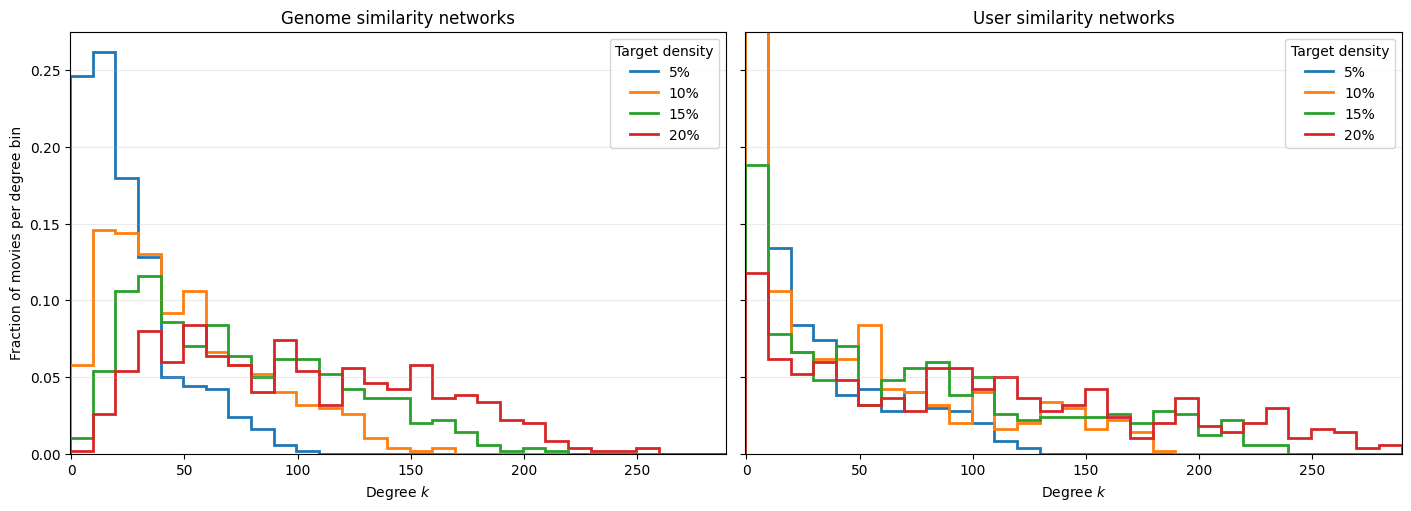

In [4]:
bin_width = 10

# Use identical bins for all eight networks.
max_degree = max(values.max() for values in degrees.values())
bin_edges = np.arange(
    -0.5,
    max_degree + bin_width + 0.5,
    bin_width
)

colors = {
    5: "tab:blue",
    10: "tab:orange",
    15: "tab:green",
    20: "tab:red",
}

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for ax, network_type in zip(axes, network_types):
    for density_pct in density_percentages:
        values = degrees[(network_type, density_pct)]

        counts, _ = np.histogram(values, bins=bin_edges)
        fractions = counts / len(values)

        ax.stairs(
            fractions,
            bin_edges,
            label=f"{density_pct}%",
            color=colors[density_pct],
            linewidth=2
        )

    ax.set_title(f"{network_type.capitalize()} similarity networks")
    ax.set_xlabel("Degree $k$")
    ax.set_xlim(-0.5, bin_edges[-1])
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(title="Target density")

axes[0].set_ylabel("Fraction of movies per degree bin")

plt.show()

### With line-graphs

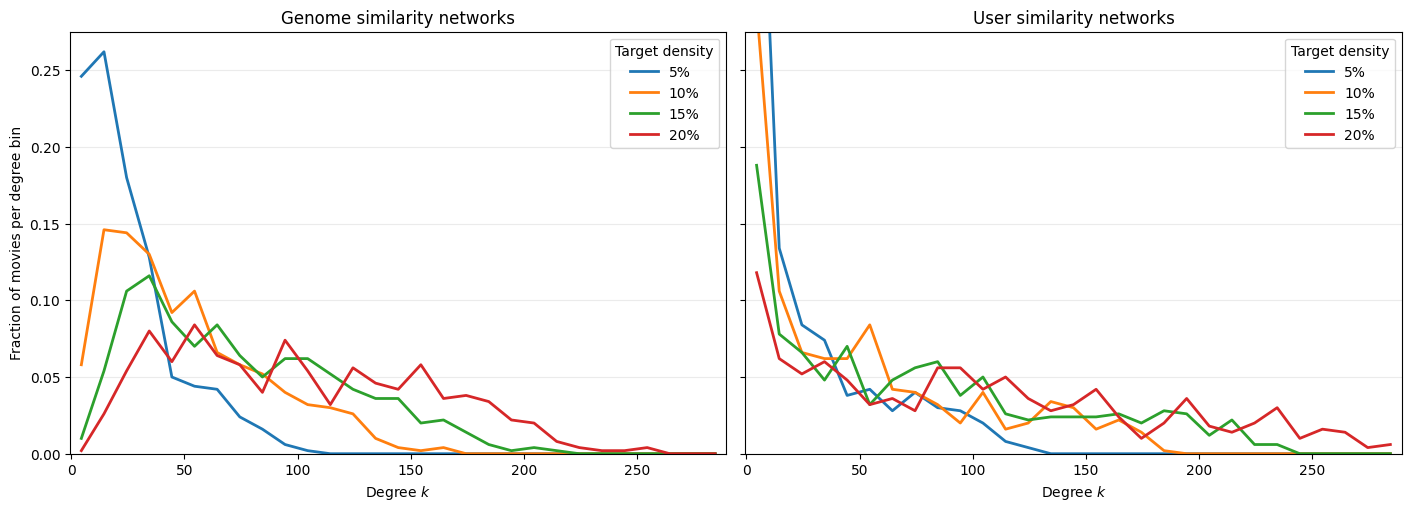

In [5]:
bin_width = 10

# Use identical bins for all eight networks.
max_degree = max(values.max() for values in degrees.values())
bin_edges = np.arange(
    -0.5,
    max_degree + bin_width + 0.5,
    bin_width
)
bin_centres = (bin_edges[:-1] + bin_edges[1:]) / 2

colors = {
    5: "tab:blue",
    10: "tab:orange",
    15: "tab:green",
    20: "tab:red",
}

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for ax, network_type in zip(axes, network_types):
    for density_pct in density_percentages:
        values = degrees[(network_type, density_pct)]

        counts, _ = np.histogram(values, bins=bin_edges)
        fractions = counts / len(values)

        ax.plot(
            bin_centres,
            fractions,
            label=f"{density_pct}%",
            color=colors[density_pct],
            linewidth=2
        )

    ax.set_title(f"{network_type.capitalize()} similarity networks")
    ax.set_xlabel("Degree $k$")
    ax.set_xlim(-0.5, bin_edges[-1])
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(title="Target density")

axes[0].set_ylabel("Fraction of movies per degree bin")

plt.show()

### Summary table

In [6]:
rows = []

for network_type in network_types:
    for density_pct in density_percentages:
        key = (network_type, density_pct)
        G = graphs[key]
        values = degrees[key]

        mean_degree = values.mean()
        sd_degree = values.std(ddof=0)
        p10, p90 = np.percentile(values, [10, 90])

        rows.append({
            "Type": network_type,
            "Target density (%)": density_pct,
            "Actual density (%)": 100 * nx.density(G),
            "Nodes": G.number_of_nodes(),
            "Edges": G.number_of_edges(),
            "Mean degree": mean_degree,
            "Degree SD": sd_degree,
            "Degree P10": p10,
            "Median degree": np.median(values),
            "Degree P90": p90,
            "Minimum degree": values.min(),
            "Maximum degree": values.max(),
            "Degree CV": (
                sd_degree / mean_degree if mean_degree > 0 else np.nan
            ),
            "Isolated movies": np.count_nonzero(values == 0),
        })

degree_summary = pd.DataFrame(rows)

# Format only the displayed table; retain full precision in the DataFrame.
display(
    degree_summary.style
    .format({
        "Target density (%)": "{:.0f}",
        "Actual density (%)": "{:.4f}",
        "Mean degree": "{:.2f}",
        "Degree SD": "{:.2f}",
        "Degree P10": "{:.2f}",
        "Median degree": "{:.2f}",
        "Degree P90": "{:.2f}",
        "Degree CV": "{:.3f}",
    })
    .hide(axis="index")
)

Type,Target density (%),Actual density (%),Nodes,Edges,Mean degree,Degree SD,Degree P10,Median degree,Degree P90,Minimum degree,Maximum degree,Degree CV,Isolated movies
genome,5,5.0004,500,6238,24.95,20.38,4.00,19.00,56.00,0,106,0.817,7
genome,10,10.0000,500,12475,49.90,34.06,14.00,41.00,100.00,0,165,0.683,1
genome,15,15.0004,500,18713,74.85,45.09,24.00,67.00,140.10,3,213,0.602,0
genome,20,20.0000,500,24950,99.80,55.17,33.00,95.00,177.10,8,257,0.553,0
user,5,5.0004,500,6238,24.95,30.78,0.00,11.00,78.00,0,122,1.234,107
user,10,10.0000,500,12475,49.90,49.80,1.00,33.50,134.00,0,181,0.998,46
user,15,15.0004,500,18713,74.85,64.22,3.00,62.00,178.20,0,239,0.858,28
user,20,20.0000,500,24950,99.80,76.08,7.90,91.00,216.40,0,289,0.762,18


## Compare 15% to ER-random and Scale-free

### Histograms

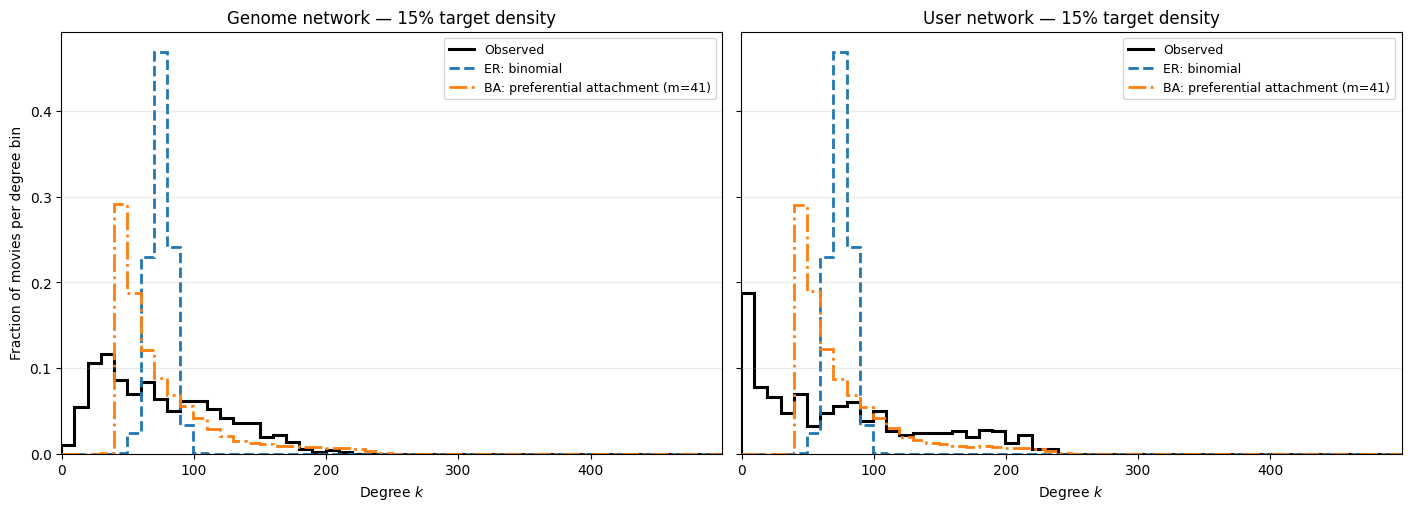

,Type,Nodes,Observed density (%),Observed mean degree,ER expected mean degree,BA parameter m,BA mean degree,BA density (%)
0,genome,500,15.0004,74.852,74.852,41,75.276,15.0854
1,user,500,15.0004,74.852,74.852,41,75.276,15.0854


In [7]:
# Settings
target_density_pct = 15
bin_width = 10
n_ba_realizations = 100
rng = np.random.default_rng(42)

comparison = {}
model_rows = []

for network_type in network_types:
    key = (network_type, target_density_pct)
    G = graphs[key]

    n = G.number_of_nodes()
    observed_edges = G.number_of_edges()
    observed_degrees = degrees[key]
    observed_mean = observed_degrees.mean()
    p = nx.density(G)

    # ER: exact marginal degree distribution:
    # K ~ Binomial(n - 1, p)
    k = np.arange(n)
    er_pmf = binom.pmf(k, n - 1, p)

    # For NetworkX's default BA construction:
    # number of edges = m * (n - m).
    # Choose the integer m that best matches the observed edge count.
    m_candidates = np.arange(1, n)
    ba_edge_counts = m_candidates * (n - m_candidates)
    m = int(
        m_candidates[
            np.argmin(np.abs(ba_edge_counts - observed_edges))
        ]
    )

    # Average over multiple BA realizations to reduce simulation noise.
    ba_counts = np.zeros(n, dtype=float)

    for _ in range(n_ba_realizations):
        seed = int(rng.integers(0, 2**32 - 1))
        G_ba = nx.barabasi_albert_graph(n=n, m=m, seed=seed)

        ba_degrees = np.array(
            [degree for _, degree in G_ba.degree()],
            dtype=int
        )
        ba_counts += np.bincount(ba_degrees, minlength=n)

    ba_pmf = ba_counts / (n_ba_realizations * n)

    comparison[network_type] = {
        "observed": observed_degrees,
        "k": k,
        "er_pmf": er_pmf,
        "ba_pmf": ba_pmf,
        "m": m,
    }

    model_rows.append({
        "Type": network_type,
        "Nodes": n,
        "Observed density (%)": 100 * p,
        "Observed mean degree": observed_mean,
        "ER expected mean degree": (n - 1) * p,
        "BA parameter m": m,
        "BA mean degree": 2 * m * (n - m) / n,
        "BA density (%)": (
            100 * (m * (n - m)) / (n * (n - 1) / 2)
        ),
    })

# Shared bins cover the full possible degree range, including model tails.
n_max = max(len(graphs[(t, target_density_pct)]) for t in network_types)
bin_edges = np.arange(-0.5, n_max + bin_width, bin_width)

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for ax, network_type in zip(axes, network_types):
    result = comparison[network_type]

    observed_counts, _ = np.histogram(
        result["observed"], bins=bin_edges
    )
    observed_fraction = observed_counts / len(result["observed"])

    # Sum the theoretical probabilities within the same histogram bins.
    er_fraction, _ = np.histogram(
        result["k"],
        bins=bin_edges,
        weights=result["er_pmf"]
    )
    ba_fraction, _ = np.histogram(
        result["k"],
        bins=bin_edges,
        weights=result["ba_pmf"]
    )

    ax.stairs(
        observed_fraction, bin_edges,
        label="Observed",
        color="black", linewidth=2.2
    )
    ax.stairs(
        er_fraction, bin_edges,
        label="ER: binomial",
        color="tab:blue", linewidth=2,
        linestyle="--"
    )
    ax.stairs(
        ba_fraction, bin_edges,
        label=f"BA: preferential attachment (m={result['m']})",
        color="tab:orange", linewidth=2,
        linestyle="-."
    )

    ax.set_title(
        f"{network_type.capitalize()} network — 15% target density"
    )
    ax.set_xlabel("Degree $k$")
    ax.set_xlim(-0.5, n_max - 0.5)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=9)

axes[0].set_ylabel("Fraction of movies per degree bin")

plt.show()

# Check how closely the reference models match the observed mean degree.
model_summary = pd.DataFrame(model_rows)
display(model_summary.round(4))

### Line-graphs

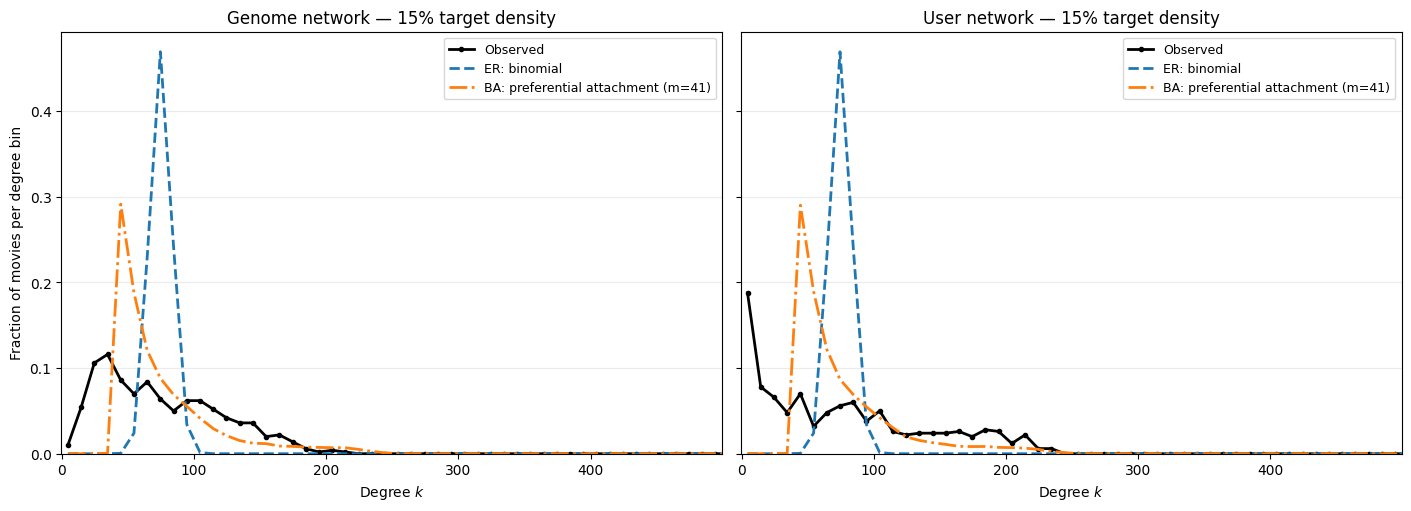

In [8]:
# Use the same bins as before.
n_max = max(
    len(graphs[(t, target_density_pct)])
    for t in network_types
)
bin_edges = np.arange(-0.5, n_max + bin_width, bin_width)
bin_centres = (bin_edges[:-1] + bin_edges[1:]) / 2

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for ax, network_type in zip(axes, network_types):
    result = comparison[network_type]

    observed_counts, _ = np.histogram(
        result["observed"], bins=bin_edges
    )
    observed_fraction = observed_counts / len(result["observed"])

    er_fraction, _ = np.histogram(
        result["k"],
        bins=bin_edges,
        weights=result["er_pmf"]
    )
    ba_fraction, _ = np.histogram(
        result["k"],
        bins=bin_edges,
        weights=result["ba_pmf"]
    )

    ax.plot(
        bin_centres, observed_fraction,
        label="Observed",
        color="black", linewidth=2,
        marker="o", markersize=3
    )
    ax.plot(
        bin_centres, er_fraction,
        label="ER: binomial",
        color="tab:blue", linewidth=2,
        linestyle="--"
    )
    ax.plot(
        bin_centres, ba_fraction,
        label=f"BA: preferential attachment (m={result['m']})",
        color="tab:orange", linewidth=2,
        linestyle="-."
    )

    ax.set_title(
        f"{network_type.capitalize()} network — 15% target density"
    )
    ax.set_xlabel("Degree $k$")
    ax.set_xlim(-0.5, n_max - 0.5)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=9)

axes[0].set_ylabel("Fraction of movies per degree bin")

plt.show()

# Edge-overlap analysis

In [9]:
def undirected_edge_set(G):
    """Represent each edge independently of its endpoint order."""
    if G.is_directed() or G.is_multigraph():
        raise ValueError("Expected a simple undirected graph.")
    if nx.number_of_selfloops(G) > 0:
        raise ValueError("Self-loops are not supported.")

    return {frozenset((u, v)) for u, v in G.edges()}


rows = []

# Keep the actual edge sets available for later movie-level analysis.
edge_comparison_sets = {}

for density_pct in [5, 10, 15, 20]:
    G_genome = graphs[("genome", density_pct)]
    G_user = graphs[("user", density_pct)]

    # Compare all movies, including isolates.
    # Node IDs must refer to the same movies in both networks.
    if set(G_genome.nodes()) != set(G_user.nodes()):
        raise ValueError(
            f"Node sets differ at {density_pct}% density. "
            "Both networks must contain the same movie IDs."
        )

    n = G_genome.number_of_nodes()
    possible_edges = n * (n - 1) // 2

    if possible_edges == 0:
        raise ValueError("At least two movies are required.")

    genome_edges = undirected_edge_set(G_genome)
    user_edges = undirected_edge_set(G_user)

    shared = genome_edges & user_edges
    genome_only = genome_edges - user_edges
    user_only = user_edges - genome_edges
    union = genome_edges | user_edges

    m_genome = len(genome_edges)
    m_user = len(user_edges)
    n_shared = len(shared)

    expected_shared = m_genome * m_user / possible_edges

    # Largest achievable intersection given the two edge counts.
    maximum_shared = min(m_genome, m_user)

    adjustment_denominator = maximum_shared - expected_shared

    rows.append({
        "Target density (%)": density_pct,
        "Genome edges": m_genome,
        "User edges": m_user,
        "Shared edges": n_shared,
        "Genome-only edges": len(genome_only),
        "User-only edges": len(user_only),
        "Genome edges shared (%)": (
            100 * n_shared / m_genome if m_genome else np.nan
        ),
        "User edges shared (%)": (
            100 * n_shared / m_user if m_user else np.nan
        ),
        "Jaccard similarity": (
            n_shared / len(union) if union else np.nan
        ),
        "Expected shared edges": expected_shared,
        "Overlap enrichment": (
            n_shared / expected_shared
            if expected_shared > 0 else np.nan
        ),
        "Chance-adjusted overlap": (
            (n_shared - expected_shared) / adjustment_denominator
            if adjustment_denominator > 0 else np.nan
        ),
    })

    edge_comparison_sets[density_pct] = {
        "shared": shared,
        "genome_only": genome_only,
        "user_only": user_only,
    }

edge_overlap_summary = pd.DataFrame(rows)

display(
    edge_overlap_summary.style
    .format({
        "Genome edges shared (%)": "{:.2f}",
        "User edges shared (%)": "{:.2f}",
        "Jaccard similarity": "{:.3f}",
        "Expected shared edges": "{:.1f}",
        "Overlap enrichment": "{:.2f}",
        "Chance-adjusted overlap": "{:.3f}",
    }, na_rep="—")
    .hide(axis="index")
)

Target density (%),Genome edges,User edges,Shared edges,Genome-only edges,User-only edges,Genome edges shared (%),User edges shared (%),Jaccard similarity,Expected shared edges,Overlap enrichment,Chance-adjusted overlap
5,6238,6238,2105,4133,4133,33.74,33.74,0.203,311.9,6.75,0.303
10,12475,12475,5073,7402,7402,40.67,40.67,0.255,1247.5,4.07,0.341
15,18713,18713,8590,10123,10123,45.90,45.90,0.298,2807.0,3.06,0.364
20,24950,24950,12540,12410,12410,50.26,50.26,0.336,4990.0,2.51,0.378


## **Edge overlap between content and audience networks**
To investigate whether movies with similar content attract similar audiences, we compared the edges of the genome and user networks at each target density. Because both networks contain the same 500 movies and the same number of edges, this comparison measures whether they select the same movie pairs as particularly similar.

The two network types overlap substantially more than expected under independent, uniform edge selection at every density. At 5% density, they share 2,105 edges, representing 33.74% of either network’s connections. The random baseline predicts approximately 312 shared edges, making the observed overlap 6.75 times larger. At 20% density, 50.26% of edges are shared, compared with an expected 20%, corresponding to an enrichment of 2.51.

These results support an association between content similarity and audience similarity: movie pairs selected for their similar content are also selected for similar audiences more often than the edge-count baseline predicts. However, the relationship is far from complete. Even at 20% density, approximately half of each network’s connections are absent from the other. Content similarity therefore captures part of the audience structure, while the two constructions retain substantial differences.

The overlap percentages are symmetric because the networks have equal edge counts. For example, at 15% density, 45.90% of genome edges also occur in the user network, and the same percentage of user edges occurs in the genome network. This symmetry follows from the construction and does not establish a direction of influence between content and audience similarity.

## **Dependence on target density**
Raw agreement increases consistently with density. The shared-edge percentage rises from 33.74% to 50.26%, while Jaccard similarity increases from 0.203 to 0.336. These values describe different denominators: the shared-edge percentage measures overlap relative to one network, whereas Jaccard similarity measures overlap relative to the union of both networks.

Some increase in raw overlap is expected simply because denser networks include more movie pairs. The two baseline-adjusted measures help interpret this:
- Overlap enrichment decreases from 6.75 to 2.51. Relative to independent random selection, the strongest retained similarities show the greatest enrichment. At low density, finding the same edge in both networks is particularly unusual under the baseline.
- Chance-adjusted overlap increases from 0.303 to 0.378. After subtracting expected overlap and scaling by the maximum possible excess overlap, agreement increases modestly as additional, weaker similarities are included.
These trends are compatible. Enrichment measures how many times larger the overlap is than a baseline that grows rapidly with density. Chance-adjusted overlap measures the fraction of the available improvement above that baseline. Thus, the sparse networks show the greatest relative enrichment, while the denser networks show greater overall agreement, including after this chance adjustment.

The main conclusion is robust across all four thresholds: content and audience connections align more than the uniform random baseline predicts, but neither network reproduces the other. The thresholds are sensitivity checks on the same underlying similarity data, rather than four independent replications.

## **Interpretation and limitations**
The incomplete overlap is consistent with content being one of several factors associated with audience composition. Movies with different tag profiles may share viewers, while content-similar movies may reach different audiences. Franchise membership, release period, language, exposure, and viewing preferences are possible contributors, but the overlap table alone cannot determine which mechanisms explain the differences.

The comparison also depends on thresholding. An edge unique to one network need not represent a movie pair with no similarity in the other: its score may simply fall below that network’s cutoff. Consequently, the results establish agreement among the selected connections, rather than measuring the full relationship between all content and audience similarity scores. A comparison of those underlying scores would complement this analysis.

Furthermore, the random baseline preserves edge counts but not individual movie degrees. Some overlap could arise because particular movies have many connections in both networks. The observed enrichment therefore demonstrates agreement beyond uniform edge selection, but does not isolate pair-specific agreement beyond shared degree patterns. A degree-preserving random comparison would provide a stricter follow-up.

# Metric comparison: assortivity, clustering, E[hopcount], small-world

**This takes a few minutes to run, shows progress with prints in after each graph**

In [10]:
# More realizations give a more stable random reference,
# but increase computation time.
n_random = 20
rng = np.random.default_rng(42)

# Reuse random references when components have the same n and m.
random_reference_cache = {}


def get_random_reference(n, m):
    """
    ER G(n, m) reference: uniformly random simple graphs with
    exactly n nodes and m edges.

    Calculate path length on each random graph's largest
    connected component if it is disconnected.
    """
    key = (n, m)

    if key in random_reference_cache:
        return random_reference_cache[key]

    clustering_values = []
    path_length_values = []
    connected_values = []
    lcc_fractions = []

    for _ in range(n_random):
        seed = int(rng.integers(0, 2**32 - 1))
        R = nx.gnm_random_graph(n, m, seed=seed)

        connected = nx.is_connected(R)
        connected_values.append(connected)

        if connected:
            R_lcc = R
        else:
            nodes = max(nx.connected_components(R), key=len)
            R_lcc = R.subgraph(nodes)

        lcc_fractions.append(len(R_lcc) / n)

        # Use the same component for both quantities in sigma.
        clustering_values.append(
            nx.average_clustering(R_lcc, weight=None)
        )
        path_length_values.append(
            nx.average_shortest_path_length(R_lcc, weight=None)
        )

    reference = {
        "C": float(np.mean(clustering_values)),
        "L": float(np.mean(path_length_values)),
        "Connected fraction": float(np.mean(connected_values)),
        "Mean LCC fraction": float(np.mean(lcc_fractions)),
    }

    random_reference_cache[key] = reference
    return reference


rows = []

for network_type in network_types:
    for density_pct in density_percentages:
        G = graphs[(network_type, density_pct)]

        n = G.number_of_nodes()
        components = list(nx.connected_components(G))
        lcc_nodes = max(components, key=len)
        H = G.subgraph(lcc_nodes)

        # Full-network metrics
        degree_values = np.array(
            [degree for _, degree in G.degree(weight=None)]
        )

        # Assortativity is undefined if all degrees are equal.
        assortativity = (
            nx.degree_assortativity_coefficient(G, weight=None)
            if np.ptp(degree_values) > 0
            else np.nan
        )

        clustering_full = nx.average_clustering(G, weight=None)
        transitivity_full = nx.transitivity(G)

        # Component metrics for path length and small-world comparison
        clustering_lcc = nx.average_clustering(H, weight=None)

        if len(H) >= 2:
            path_length_lcc = nx.average_shortest_path_length(
                H, weight=None
            )

            reference = get_random_reference(
                H.number_of_nodes(),
                H.number_of_edges()
            )

            clustering_ratio = (
                clustering_lcc / reference["C"]
                if reference["C"] > 0 else np.nan
            )
            path_length_ratio = (
                path_length_lcc / reference["L"]
                if reference["L"] > 0 else np.nan
            )
            sigma = (
                clustering_ratio / path_length_ratio
                if path_length_ratio > 0 else np.nan
            )
        else:
            path_length_lcc = np.nan
            reference = {
                "C": np.nan,
                "L": np.nan,
                "Connected fraction": np.nan,
                "Mean LCC fraction": np.nan,
            }
            clustering_ratio = np.nan
            path_length_ratio = np.nan
            sigma = np.nan

        rows.append({
            "Type": network_type,
            "Target density (%)": density_pct,
            "Actual density (%)": 100 * nx.density(G),
            "Components": len(components),
            "LCC nodes": len(H),
            "LCC (%)": 100 * len(H) / n,
            "Degree assortativity": assortativity,
            "Mean clustering": clustering_full,
            "Transitivity": transitivity_full,
            "Mean clustering (LCC)": clustering_lcc,
            "Mean hopcount (LCC)": path_length_lcc,
            "ER mean clustering": reference["C"],
            "ER mean hopcount": reference["L"],
            "C / C_ER": clustering_ratio,
            "L / L_ER": path_length_ratio,
            "Small-world sigma": sigma,
            "ER connected (%)": (
                100 * reference["Connected fraction"]
            ),
            "ER mean LCC (%)": (
                100 * reference["Mean LCC fraction"]
            ),
        })

        print(f"Finished: {network_type}, {density_pct}%")

network_summary = pd.DataFrame(rows)

# Main table
main_columns = [
    "Type",
    "Target density (%)",
    "Components",
    "LCC (%)",
    "Degree assortativity",
    "Mean clustering",
    "Transitivity",
    "Mean hopcount (LCC)",
    "C / C_ER",
    "L / L_ER",
    "Small-world sigma",
]

display(
    network_summary[main_columns].style
    .format({
        "LCC (%)": "{:.1f}",
        "Degree assortativity": "{:.3f}",
        "Mean clustering": "{:.3f}",
        "Transitivity": "{:.3f}",
        "Mean hopcount (LCC)": "{:.3f}",
        "C / C_ER": "{:.3f}",
        "L / L_ER": "{:.3f}",
        "Small-world sigma": "{:.3f}",
    }, na_rep="—")
    .hide(axis="index")
)

# All reference values and diagnostics remain available:
# display(network_summary.round(4))

Finished: genome, 5%
Finished: genome, 10%
Finished: genome, 15%
Finished: genome, 20%
Finished: user, 5%
Finished: user, 10%
Finished: user, 15%
Finished: user, 20%


Type,Target density (%),Components,LCC (%),Degree assortativity,Mean clustering,Transitivity,Mean hopcount (LCC),C / C_ER,L / L_ER,Small-world sigma
genome,5,8,98.6,0.467,0.552,0.517,3.199,10.863,1.450,7.493
genome,10,2,99.8,0.400,0.584,0.536,2.444,5.830,1.283,4.544
genome,15,1,100.0,0.360,0.602,0.556,2.142,4.009,1.158,3.462
genome,20,1,100.0,0.324,0.619,0.579,1.957,3.095,1.087,2.847
user,5,110,77.8,0.196,0.466,0.521,2.711,7.237,1.368,5.291
user,10,49,90.0,0.110,0.578,0.554,2.406,5.202,1.282,4.059
user,15,30,94.0,0.066,0.639,0.582,2.147,4.006,1.173,3.414
user,20,19,96.4,0.022,0.668,0.604,2.010,3.218,1.126,2.858


## Comments on the metrics

### **Connectivity: audience similarity leaves more movies outside the main component**

The genome networks are consistently more connected. At 5% density, the genome network already contains 98.6% of movies in its largest connected component, compared with 77.8% for the user network. The genome network becomes fully connected at 15%, whereas the user network still has 19 components at 20%.

Because the networks have the same number of nodes and edges at each density, this difference reflects how the edges are allocated, rather than how many edges are available. In the user networks, the retained audience similarities concentrate connections among a subset of movies, leaving more movies disconnected from the main network.

Moreover, the component counts indicate that most movies outside the user LCC are isolated. At 5%, for example, 111 movies are spread across 109 remaining components; at 15% and 20%, every movie outside the LCC is isolated. Thus, the fragmentation primarily reflects individual movies with no retained connections, rather than several large, separate audience groups.

This distinction matters for interpretation. An isolated movie does not necessarily have no audience or an entirely unique audience. It means that none of its pairwise similarities survived the global selection of the strongest edges. Even among the 500 most-rated movies, differences in audience composition, rating coverage, and the similarity measure can affect which movies cross that threshold.

The pattern is robust across densities: adding edges reduces fragmentation in both types, but the user network remains less connected throughout.

### **Degree assortativity: content networks have more pronounced sorting by degree**

Both network types show positive degree assortativity, but it is substantially stronger in the genome networks:
- Genome assortativity decreases from 0.467 to 0.324.
- User assortativity decreases from 0.196 to 0.022.
Positive assortativity means that movies with many connections tend to connect to other movies with many connections. For the genome networks, a movie with many content-similar neighbours therefore tends to connect to movies that also have many content-similar neighbours.

One plausible explanation is that densely represented regions of the tag space contain many mutually similar movies. Movies in those regions acquire high degrees and connect to one another, whereas movies in more sparsely represented regions have fewer neighbours. The statistics are consistent with this explanation, although examining genres or tag profiles would be needed to verify it.

The user networks show much weaker sorting by degree. At 20%, the coefficient of 0.022 indicates almost no linear correlation between the degrees at the two ends of an edge. A movie with many audience-similar neighbours can therefore connect to movies spanning a broader range of degrees.

This is not a measure of whether audiences prefer similar content, nor does low assortativity imply weak communities. It describes similarity in the number of connections at adjacent nodes.

The decline with increasing density occurs in both constructions. As progressively weaker similarities are admitted, degree-based sorting becomes less pronounced. The genome–user difference nevertheless remains clear at every density, making it one of the strongest structural distinctions in the table.

**Clustering: both networks contain strongly interconnected neighbourhoods**
Both network types have high clustering across all densities. If two movies are connected to the same movie, they frequently connect to each other as well.

This is compatible with the construction of both networks. In the genome network, neighbours share similar tag profiles; in the user network, neighbours have similar audience vectors. Thresholding similarities between vectors can itself encourage triangle formation, so high clustering should be interpreted partly as a property of the similarity-based construction, rather than solely as independent evidence of social or audience organisation.

The mean clustering coefficient increases monotonically:
- Genome: 0.552 → 0.619
- User: 0.466 → 0.668
The ranking changes with density. Genome networks have higher mean clustering at 5% and marginally at 10%, while user networks have higher clustering at 15% and 20%.

However, isolated nodes affect this comparison. In the reported full-network average, movies with fewer than two neighbours contribute zero. The many isolated movies in the sparse user networks depress their mean clustering. As density increases and more movies acquire connections, that average can rise partly because fewer nodes contribute zero, as well as because neighbourhoods become more interconnected.

Transitivity helps clarify the comparison. It is very similar between the two network types at 5%—0.517 for genome and 0.521 for user—and is consistently somewhat higher for user networks thereafter. Unlike mean clustering, transitivity weights neighbourhoods according to the number of connected triples they contain.

Together, these measures suggest that the connected, triangle-forming parts of the audience networks are already strongly clustered at low density, despite the lower full-network mean. At higher densities, both clustering measures indicate somewhat stronger triangle closure in the user networks.

### **Path lengths: strong convergence at higher densities**

Average shortest-path lengths decrease as density increases, as expected when more direct connections and shortcuts become available:
- Genome: 3.199 → 1.957 hops
- User: 2.711 → 2.010 hops
At 10% and especially 15%, the two network types have very similar average path lengths. At 15%, they differ by only 0.005 hops. At 20%, both are close to two hops.

The apparent advantage of the user network at 5% requires care. Its path length is measured among only the 77.8% of movies in its LCC, whereas the genome LCC includes 98.6%. Excluding disconnected movies means these averages describe different populations. A shorter user-network path length therefore does not mean that the full audience network is easier to traverse.

At higher densities, this comparability improves as the user LCC grows, although it still excludes 18 movies at 20%. The strongest supported conclusion is that movies within the main connected components are separated by similarly short paths at moderate and high densities.

These paths also have a specific meaning: a two-hop path represents a chain of two retained similarity relationships. It does not imply that the endpoint movies themselves have high similarity, or that audiences move between them.

### **Small-world structure: strong clustering with relatively short paths**
All eight networks have $\sigma>1$, ranging from approximately 2.85 to 7.49. Their largest connected components therefore show small-world characteristics relative to the ER reference used here: substantially enhanced clustering alongside comparatively modest increases in path length.

The underlying ratios make this clearer:
- Clustering is approximately 3.1–10.9 times the random reference.
- Path length is approximately 1.09–1.45 times the random reference.
The evidence is particularly straightforward at higher densities, where path lengths approach those of the random reference while clustering remains several times greater.

At 15% and 20%, the two network types have almost identical small-world coefficients. This convergence suggests that their connected components have similar balances of local clustering and global reachability, despite their differences in assortativity and fragmentation.

The decrease in $\sigma$ with density should not be interpreted as declining observed clustering: observed clustering actually increases. Instead, random graphs become more clustered as density increases, so the observed networks’ relative clustering advantage shrinks.

Two qualifications are important:
1. For disconnected graphs, these results describe the LCC. In particular, a high small-world coefficient for the 5% user network does not describe connectivity among all 500 movies.
2. The ER reference preserves node and edge counts, but not degrees. A degree-preserving random comparison would help determine whether the clustering remains unusually high after accounting for degree heterogeneity.
The LCC reference graphs can also have different densities from the full networks. Thus, the reported ratios compare each LCC with its own matched random reference; they are not all comparisons against an ER graph at exactly the nominal target density.

### What holds across densities?

The clearest persistent patterns are:

| Finding | Consistency across densities |
| --- | --- |
| Genome networks have larger connected components and fewer components | Holds at every density |
| Genome networks have stronger degree assortativity | Holds at every density |
| Assortativity decreases as density increases | Holds for both types |
| Mean clustering and transitivity increase with density | Holds for both types |
| Average LCC path length decreases with density | Holds for both types |
| User networks have higher mean clustering | Holds only at 15% and 20% |
| User networks have higher transitivity | Holds at every density, with a very small difference at 5% |
| Small-world coefficients converge between types | Clear at 15% and 20% |

These are **sensitivity checks across thresholds, rather than independent replications**: the networks are constructed from the same similarity scores, and increasing density generally retains existing edges while adding weaker ones. Nevertheless, the persistence of the connectivity and assortativity differences shows that they are not specific to one chosen threshold.

## **Implications for the research question**
For “Do movies with similar content attract similar audiences?”, these results provide useful structural context, but not yet a direct answer. Two networks could have nearly identical clustering and path lengths while connecting entirely different movie pairs. Conversely, substantial edge overlap can coexist with differences in aggregate statistics.

The present evidence supports the narrower conclusion that:
>Content-based and audience-based movie networks both contain strongly clustered neighbourhoods and short paths within their main components. However, audience-based connections leave more movies isolated, while content-based connections exhibit consistently stronger degree assortativity. These distinctions persist across the tested densities, even as clustering and path-length measures become more similar.

Directly testing content–audience alignment would next require comparing the similarity scores, retained edges, or community memberships for the same movies.

For “Which movies connect otherwise distinct audience communities?”, the table establishes that local clustering coexists with short routes through the main audience component. It does not identify the movies responsible for those routes. That requires node-level analysis, ideally combining audience-community detection with betweenness centrality and the distribution of each movie’s connections across communities. High degree alone would not establish a bridging role.

Finally, the interpretation of “audience” should match the vector definition used in the notebook. A binary indicator of any rating measures overlap among users who rated the movies; a binary indicator of positive ratings only measures overlap among users who rated them positively. Neither directly observes every viewer. Keeping that distinction explicit will make the eventual answer to the research question more precise.

# Clustering analysis: community discovery

## Comments on methodology

We identified communities in the genome-based and user-based movie networks at 15% target density using the Louvain algorithm. Communities represent groups of movies with an excess of internal connections relative to a degree-based reference model. Louvain was selected because it provides a practical modularity-based method available within our existing NetworkX workflow and does not require a predefined number of communities.

Both networks were treated as unweighted, consistent with the preceding structural analysis. Consequently, community detection uses the presence of retained similarity connections rather than their original similarity scores. The resolution parameter was fixed at 1 for both networks, providing a common initial setting without tuning the partition to movie genres or other metadata.

Because Louvain depends on random node ordering, we repeated the analysis using 30 random seeds. We assessed variability through the number of communities, modularity scores, and pairwise adjusted Rand indices between runs. The highest-modularity partition among these runs was retained for subsequent analysis. This is the best solution found in the repeated search, rather than a guaranteed global optimum or a consensus partition.

Isolated movies were excluded from community detection and retained separately as unassigned. Their absence of retained edges provides no evidence for assigning them to a connected group. All non-isolated movies were included, including any belonging to smaller connected components. We also checked whether detected communities were internally connected.

The resulting partitions describe structure in the thresholded movie-similarity networks. In the user-based network, these are communities of movies connected by audience similarity, rather than directly observed social communities of users. Genres, release years, franchises, and genome tags will subsequently be used to interpret the detected groups; they were not used to define them.

Stability across seeds addresses only variability in the optimisation procedure. The partitions remain conditional on the chosen density and resolution, and modularity optimisation can merge smaller groups. A later sensitivity analysis at another density and alternative resolutions will therefore be needed before treating particular community boundaries as robust.

## Detect communities and evaluate stability

In [11]:
COMMUNITY_DENSITY = 15
COMMUNITY_RESOLUTION = 1.0
COMMUNITY_SEEDS = list(range(30))

community_results = {}


def detect_communities(G, seeds, resolution=1.0):
    """Repeated unweighted Louvain, with isolates excluded from fitting."""
    if G.is_directed() or G.is_multigraph():
        raise ValueError("Expected a simple undirected graph.")
    if nx.number_of_selfloops(G):
        raise ValueError("Remove self-loops before community detection.")
    if len(seeds) < 2:
        raise ValueError("Use at least two seeds to assess stability.")

    isolates = set(nx.isolates(G))
    active_nodes = sorted(set(G) - isolates, key=str)

    if not active_nodes:
        raise ValueError("No edges remain: community detection is undefined.")

    H = G.subgraph(active_nodes).copy()
    runs = []

    for seed in seeds:
        partition = nx.community.louvain_communities(
            H,
            weight=None,          # Explicitly ignore similarity weights.
            resolution=resolution,
            seed=seed,
        )

        # Number communities by decreasing size; break ties deterministically.
        # These labels are identifiers, not matched labels across networks/runs.
        partition = sorted(
            [set(nodes) for nodes in partition],
            key=lambda nodes: (
                -len(nodes),
                tuple(sorted(map(str, nodes))),
            ),
        )

        membership = {
            node: community_id
            for community_id, nodes in enumerate(partition, start=1)
            for node in nodes
        }

        runs.append({
            "seed": seed,
            "partition": partition,
            "membership": membership,
            "labels": np.array([membership[n] for n in active_nodes]),
            "modularity": nx.community.modularity(
                H, partition, weight=None, resolution=resolution
            ),
            "n_communities": len(partition),
            "disconnected_communities": sum(
                not nx.is_connected(H.subgraph(nodes))
                for nodes in partition
            ),
        })

    # Compare every pair of runs on the same ordered, non-isolated movies.
    n_runs = len(runs)
    ari_matrix = np.eye(n_runs)

    for i, j in combinations(range(n_runs), 2):
        ari_matrix[i, j] = ari_matrix[j, i] = adjusted_rand_score(
            runs[i]["labels"], runs[j]["labels"]
        )

    # Highest modularity; use the smaller seed if scores tie exactly.
    best_index = max(
        range(n_runs),
        key=lambda i: (runs[i]["modularity"], -runs[i]["seed"]),
    )
    best = runs[best_index]

    run_table = pd.DataFrame([
        {
            "seed": run["seed"],
            "modularity": run["modularity"],
            "n_communities": run["n_communities"],
            "disconnected_communities": run["disconnected_communities"],
            "mean_ARI_to_other_runs": (
                (ari_matrix[i].sum() - 1) / (n_runs - 1)
            ),
            "selected": i == best_index,
        }
        for i, run in enumerate(runs)
    ])

    return {
        "graph": H,
        "isolates": isolates,
        "nodes": active_nodes,
        "runs": runs,
        "run_table": run_table,
        "ari_matrix": ari_matrix,
        "pairwise_ari": ari_matrix[np.triu_indices(n_runs, k=1)],
        "selected_seed": best["seed"],
        "modularity": best["modularity"],
        "communities": best["partition"],
        "membership": best["membership"],
    }


for network_type in ["genome", "user"]:
    G = graphs[(network_type, COMMUNITY_DENSITY)]

    community_results[network_type] = detect_communities(
        G,
        seeds=COMMUNITY_SEEDS,
        resolution=COMMUNITY_RESOLUTION,
    )

    result = community_results[network_type]
    print(
        f"{network_type.capitalize()}: "
        f"{len(result['communities'])} communities; "
        f"Q = {result['modularity']:.4f}; "
        f"selected seed = {result['selected_seed']}; "
        f"{len(result['isolates'])} isolates excluded."
    )

    if result["run_table"]["disconnected_communities"].max() > 0:
        print(
            "  Warning: some runs contain internally disconnected communities. "
            "Inspect run_table before interpreting the partition."
        )

Genome: 5 communities; Q = 0.3905; selected seed = 11; 0 isolates excluded.
User: 5 communities; Q = 0.2943; selected seed = 29; 28 isolates excluded.


## Summary of community detection and stability

In [12]:
summary_rows = []

for network_type, result in community_results.items():
    run_table = result["run_table"]
    pairwise_ari = result["pairwise_ari"]
    selected = run_table.loc[run_table["selected"]].iloc[0]

    summary_rows.append({
        "Type": network_type,
        "Movies analysed": len(result["nodes"]),
        "Isolated movies": len(result["isolates"]),
        "Selected seed": result["selected_seed"],
        "Selected communities": len(result["communities"]),
        "Selected modularity": result["modularity"],
        "Minimum modularity": run_table["modularity"].min(),
        "Maximum modularity": run_table["modularity"].max(),
        "Minimum communities": run_table["n_communities"].min(),
        "Maximum communities": run_table["n_communities"].max(),
        "Mean pairwise ARI": pairwise_ari.mean(),
        "Minimum pairwise ARI": pairwise_ari.min(),
        "Selected mean ARI": selected["mean_ARI_to_other_runs"],
        "Selected disconnected communities": int(
            selected["disconnected_communities"]
        ),
    })

community_detection_summary = pd.DataFrame(summary_rows)
display(community_detection_summary.round(4))

# Detailed diagnostics for individual seeds:
# display(community_results["genome"]["run_table"].round(4))
# display(community_results["user"]["run_table"].round(4))

,Type,Movies analysed,Isolated movies,Selected seed,Selected communities,Selected modularity,Minimum modularity,Maximum modularity,Minimum communities,Maximum communities,Mean pairwise ARI,Minimum pairwise ARI,Selected mean ARI,Selected disconnected communities
0,genome,500,0,11,5,0.3905,0.3711,0.3905,3,5,0.8542,0.5224,0.9035,0
1,user,472,28,29,5,0.2943,0.2827,0.2943,4,6,0.7125,0.4197,0.7651,0


## Store movie memberships and community sizes

In [13]:
# Convenient dictionaries for later analysis:
# communities["user"] -> list of sets of movie IDs
# community_membership["user"][movie_id] -> community number

communities = {
    network_type: result["communities"]
    for network_type, result in community_results.items()
}

community_membership = {
    network_type: result["membership"]
    for network_type, result in community_results.items()
}

membership_rows = []
size_rows = []

for network_type, result in community_results.items():
    G = graphs[(network_type, COMMUNITY_DENSITY)]

    for movie_id in sorted(G.nodes(), key=str):
        is_isolate = movie_id in result["isolates"]

        membership_rows.append({
            "network_type": network_type,
            "movieId": movie_id,  # Preserve the original GraphML node ID.
            "community": result["membership"].get(movie_id, pd.NA),
            "status": "isolate" if is_isolate else "assigned",
            "degree": G.degree(movie_id, weight=None),
        })

    for community_id, nodes in enumerate(
        result["communities"], start=1
    ):
        size_rows.append({
            "network_type": network_type,
            "community": community_id,
            "movies": len(nodes),
            "percent_of_assigned_movies": (
                100 * len(nodes) / len(result["nodes"])
            ),
            "connected": nx.is_connected(G.subgraph(nodes)),
        })

community_assignments = pd.DataFrame(membership_rows)
community_assignments["community"] = (
    community_assignments["community"].astype("Int64")
)

community_sizes = pd.DataFrame(size_rows)

display(community_sizes.round(2))
display(community_assignments.head(10))

,network_type,community,movies,percent_of_assigned_movies,connected
0,genome,1,172,34.40,True
1,genome,2,131,26.20,True
2,genome,3,93,18.60,True
3,genome,4,52,10.40,True
4,genome,5,52,10.40,True
5,user,1,182,38.56,True
6,user,2,171,36.23,True
7,user,3,108,22.88,True
8,user,4,9,1.91,True
9,user,5,2,0.42,True


,network_type,movieId,community,status,degree
0,genome,1,4,assigned,69
1,genome,10,5,assigned,33
2,genome,1028,4,assigned,45
3,genome,1035,4,assigned,16
4,genome,1036,5,assigned,206
5,genome,104,3,assigned,52
6,genome,104841,2,assigned,65
7,genome,106782,1,assigned,110
8,genome,106920,1,assigned,108
9,genome,1073,4,assigned,36
